In [1]:
import os
os.environ['PYTHONPATH'] = '/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master'

In [2]:
import numpy as np, matplotlib.pyplot as plt, numba, os, random, scipy, subprocess
import scipy.stats as st, sys, seaborn as sns, pandas as pd, matplotlib.pyplot as plt, sys
from sklearn.metrics import confusion_matrix
from joblib import Parallel, delayed

In [3]:
import sys
sys.path.insert(0, '/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master')  # the folder CONTAINING bench/

import bench
print(bench.__file__)  # should point into your bench-master folder, not site-packages

from bench.diffusion_models import sample_signal, sm_w_soma

/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/__init__.py


In [11]:
bvecs = "/Users/ecd25/Desktop/BENCH/one_versus_many/protocols/pre_bvecs"
bvals = "/Users/ecd25/Desktop/BENCH/one_versus_many/protocols/pre_bvals"
standard_model_dt = "/Users/ecd25/Desktop/BENCH/Soma_Model/trained_models/ss_preop_standard_model_w_soma_dt"

In [ ]:
!bench diff-train --model sm_w_soma --bvals $bvals --summarytype dt --output $standard_model_dt

In [6]:
from bench import diffusion_models, model_inversion, change_model, acquisition, plot

In [12]:
forward_model = diffusion_models.sm_w_soma
shm_deg = 2

acq = acquisition.Acquisition.from_bval_bvec(bvals, bvecs, b0_threshold=0.5)
func_bench, measurement_names = change_model.summary_decorator(
    forward_model, bvals=acq.bvals, bvecs=acq.bvecs, summary_type='sh', sh_degree=2)
priors_bench = diffusion_models.prior_distributions[forward_model.__name__]

In [13]:
tr = change_model.Trainer(
    forward_model=func_bench, 
    kwargs={'noise_std':0},
    priors=priors_bench, 
    measurement_names=measurement_names)

mdl = tr.train(n_samples=200, verbose=1)

Generating 200 training samples...
Training models of change for ['s_iso', 's_in', 's_ex', 's_soma', 'odi', 'd_iso', 'd_in', 'd_ex', 'tau']. /rThis may take up to a few hours depending on the number of samples and the number of change vectors.
Processing Jobs: 100%|██████████| 9/9 [00:00<00:00, 14535.52it/s]
 mu optimization for s_soma: Optimization terminated successfully.
 function value:4.636664558791918e-09, 98
 mu optimization for s_iso: Optimization terminated successfully.
 function value:0.014713839901776493, 144
 mu optimization for d_iso: Optimization terminated successfully.
 function value:0.004649317356714171, 147
 mu optimization for d_ex: Optimization terminated successfully.
 function value:2.1526940275660627, 176
 mu optimization for d_in: Optimization terminated successfully.
 function value:2.449846612358576, 177
 sigma optimization for s_soma: Desired error not necessarily achieved due to precision loss.
 function value:-192.2398126564268, 112
 mu optimization for s

In [14]:
n_test_samples = 100
noise_level = 0.02
effect_size = 0.3

true_change, data, data2, sn = tr.generate_test_samples(
        n_samples=n_test_samples, noise_std=noise_level, n_repeats=50, effect_size=effect_size, parallel=True)
    
probs, infered_change_bench, amount, _ = mdl.infer(data, data2 - data, sn)

Generating 100 test samples:
Processing Jobs: 100%|██████████| 100/100 [00:04<00:00, 21.02it/s]
running inference for 100 samples ...
Processing Jobs: 100%|██████████| 100/100 [00:03<00:00, 25.71it/s]
number of samples with nan posterior: 0


<Axes: title={'center': 'BENCH: SM w Soma (dot) - b1.2k'}, xlabel='Actual change', ylabel='Inferred Change'>

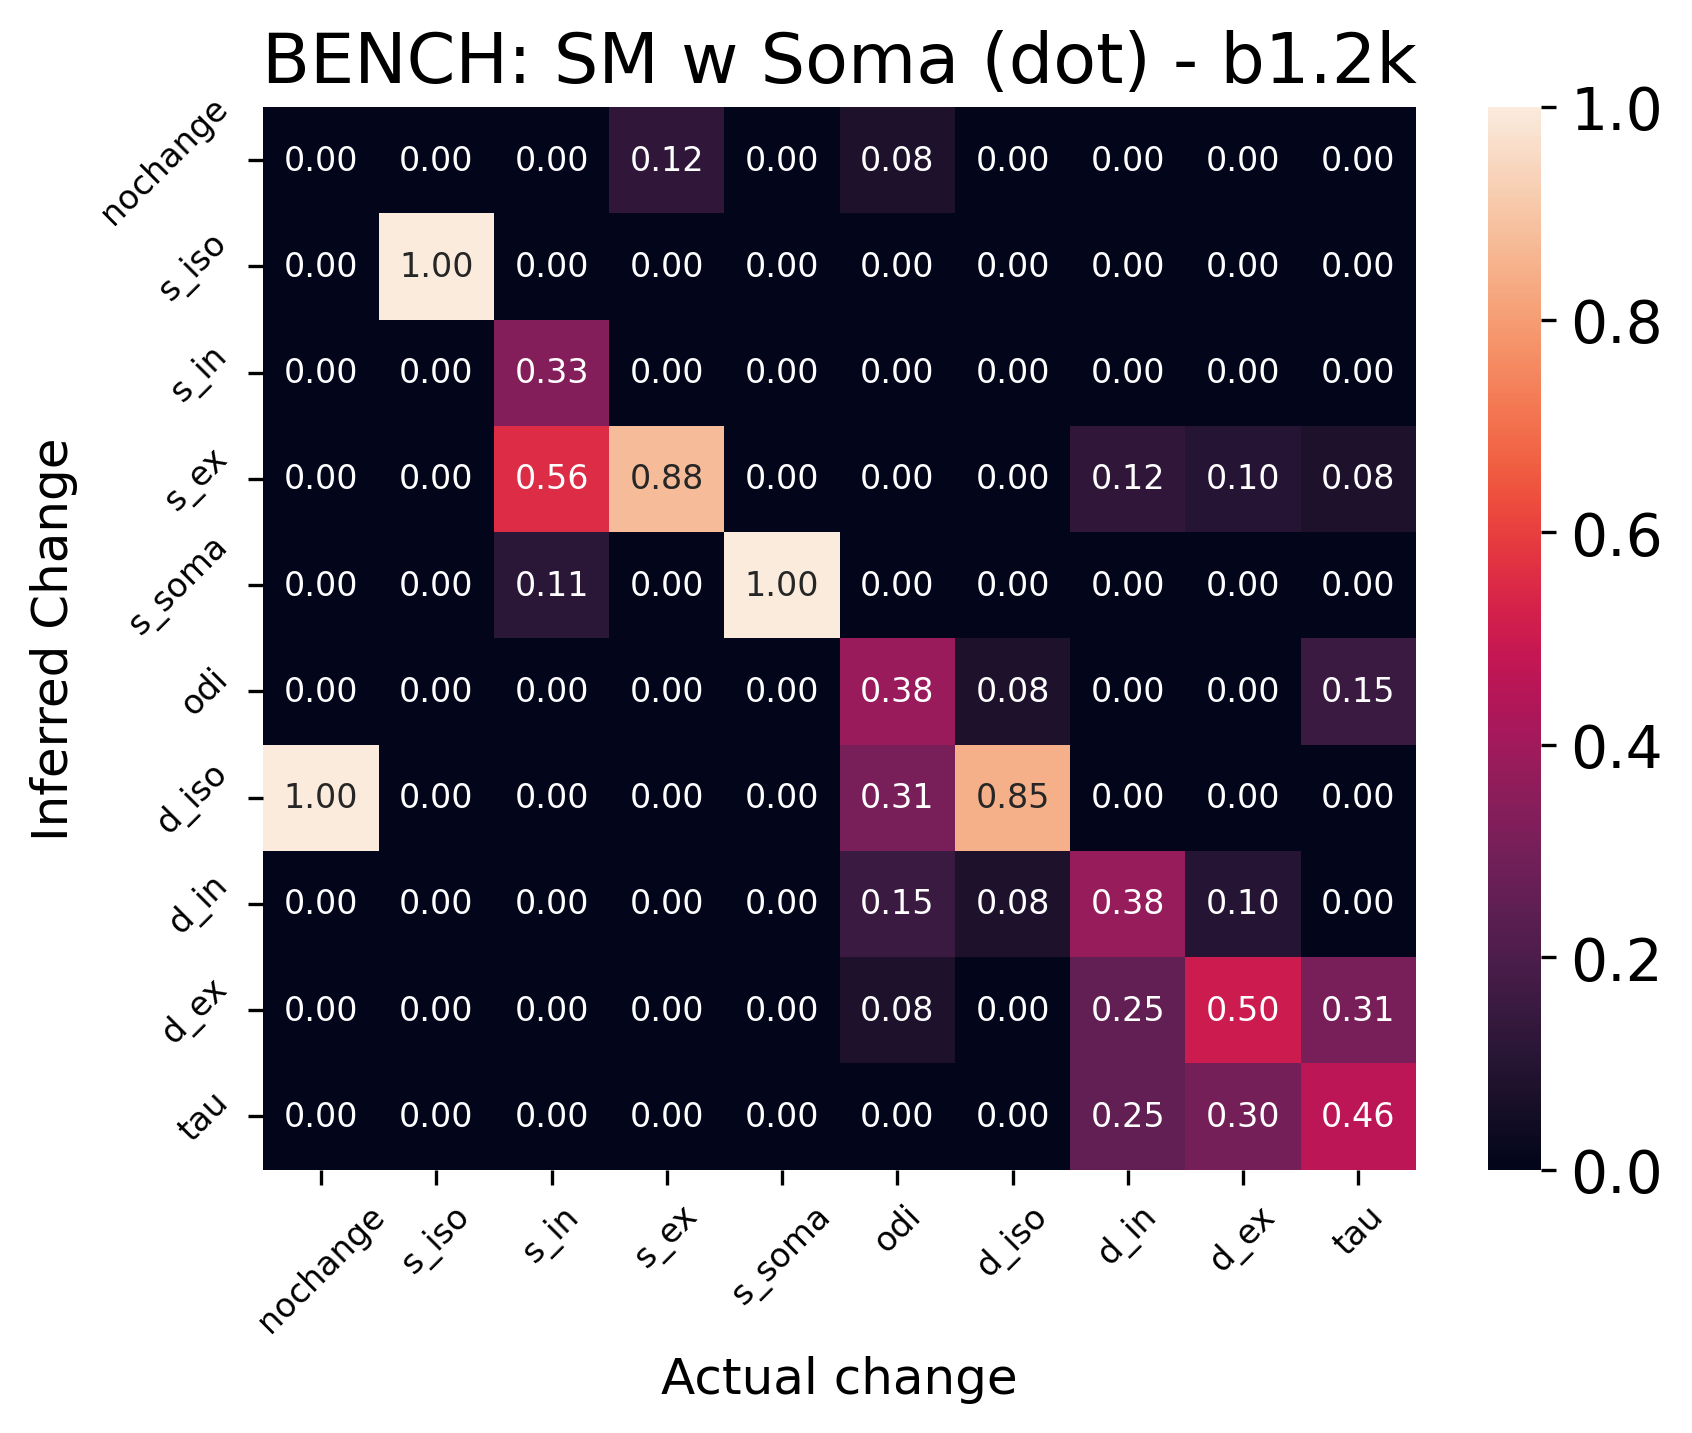

In [15]:
conf_mat = confusion_matrix(true_change, infered_change_bench, normalize='true')
plot.plot_conf_mat(conf_mat, param_names=mdl.model_names, title='BENCH: SM w Soma (dot) - b1.2k')

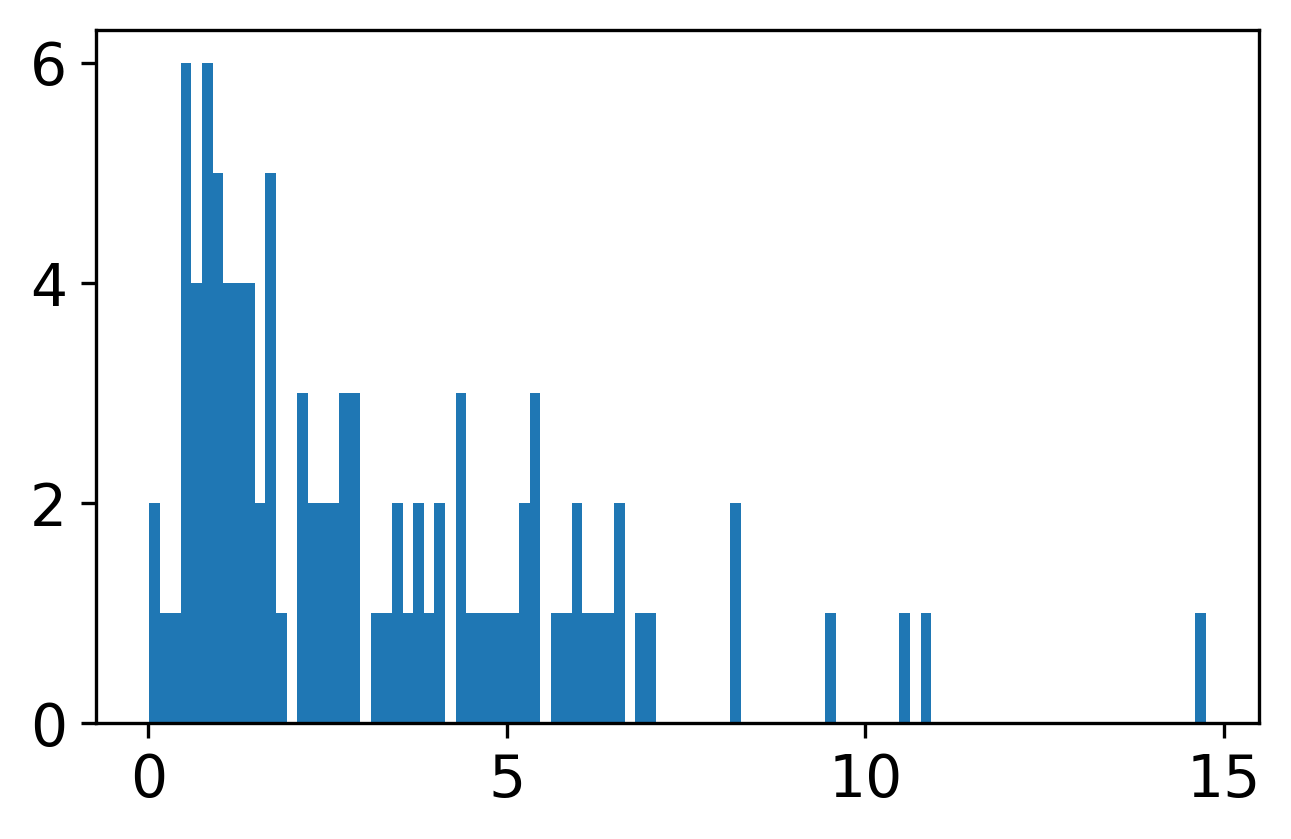

In [16]:
dv, offset, deviation = mdl.estimate_quality_of_fit(data, data2 - data, sn, infered_change_bench, amount)
plt.hist(deviation, 100);

In [17]:
def model_inv_tr(acq, noise_level, **p):
    return forward_model(bval=acq.bvals, bvec=acq.bvecs,**p) + noise_level * np.random.randn(acq.bvecs.shape[0])

def model_inv(**p):
    return forward_model(bval=acq.bvals, bvec=acq.bvecs,**p)

priors_inv = dict()
priors_inv['s_iso'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_in'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_ex'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_soma'] = st.truncnorm(loc=.05, scale=.03, a=-.05 / .03, b=np.inf)
priors_inv.update(priors_bench)
del priors_inv[('s_iso', 's_in', 's_ex', 's_soma')]

tr_inv = change_model.Trainer(forward_model=model_inv_tr, kwargs={'noise_level':0, 'acq':acq}, priors=priors_inv)

true_change_inv, sig1, sig2, sn = tr_inv.generate_test_samples(parallel=False, 
    n_samples=n_test_samples, noise_std=noise_level, n_repeats=2, effect_size=effect_size)
    
def tmp_func(j):
    pe1, std1 = model_inversion.map_fit(sig1[j], np.eye(len(sig1[j])), model_inv, priors_inv)
    pe2, std2 = model_inversion.map_fit(sig2[j], np.eye(len(sig2[j])), model_inv, priors_inv)
        
    return model_inversion.infer_change(np.atleast_2d(pe1), np.atleast_2d(std1), 
                                        np.atleast_2d(pe2), np.atleast_2d(std2), alpha=0.05)

res = Parallel(n_jobs=-1, verbose=True)(delayed(tmp_func)(j) for j in range(n_test_samples))
infered_change_inv = np.squeeze(np.array(res)[:, 0])

Generating 100 test samples:


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    8.4s
/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/Desktop/BENCH/BENCH_Ada

<Axes: title={'center': 'Parameter estimation: SM w Soma (no r)'}, xlabel='Actual change', ylabel='Inferred Change'>

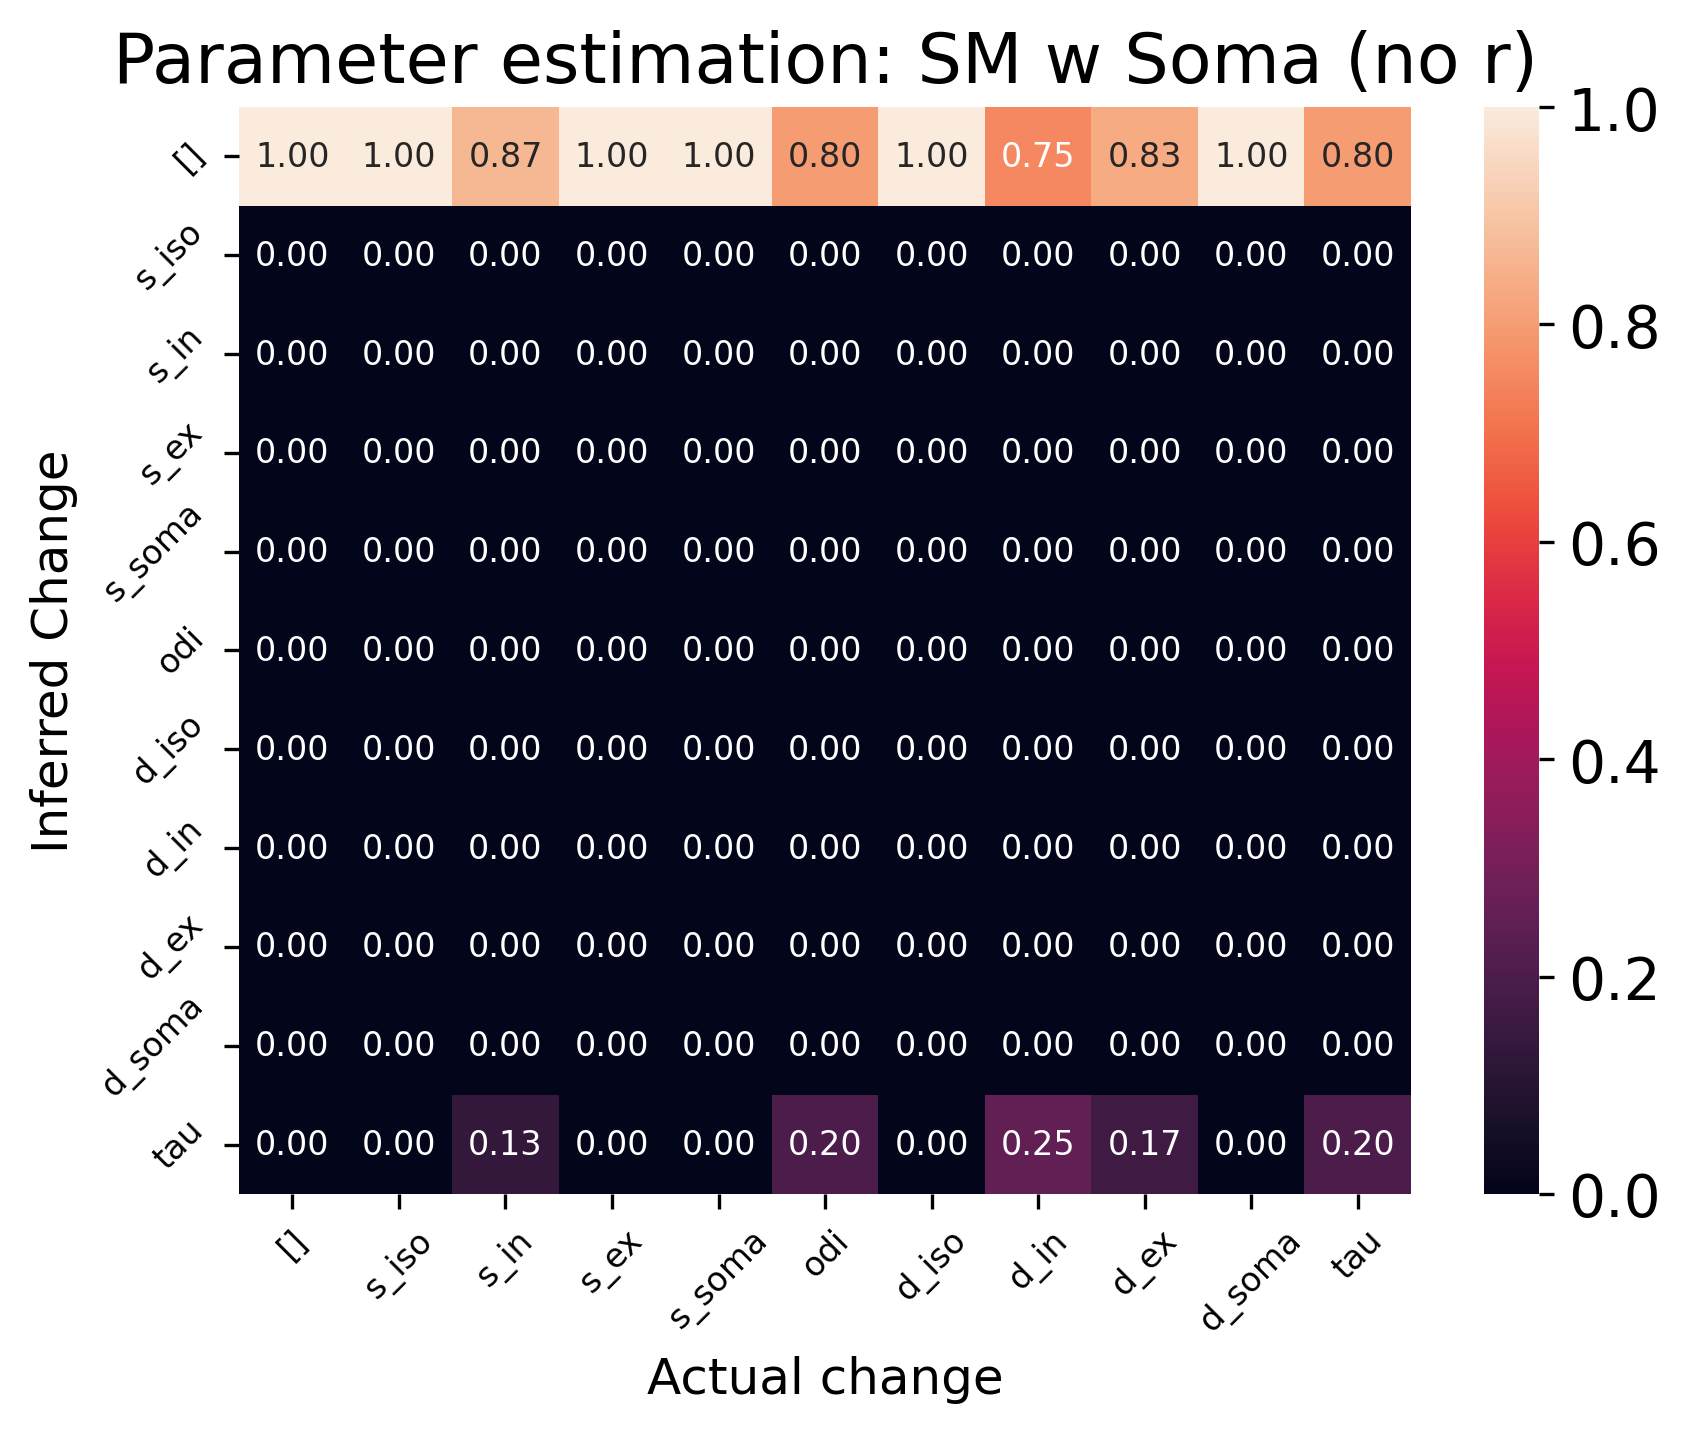

In [18]:
conf_mat_inv = confusion_matrix(true_change_inv, infered_change_inv, normalize='true')
plot.plot_conf_mat(conf_mat_inv, ['[]'] + list(priors_inv.keys()), title='Parameter estimation: SM w Soma (no r)')